# MMIP HW5

## 0. 環境與匯入

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import argparse
import sys
import time
import traceback
from pathlib import Path

from IPython.display import display

BASE_DIR = Path.cwd().resolve()          # notebook 所在目錄 = 專案根目錄
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.utils import ensure_dir, get_logger, resolve_device

logger = get_logger()
print("專案根目錄：", BASE_DIR)

專案根目錄： /root/MMIP/MMIP/HW5


## 1. 參數設定

In [2]:
def parse_args(argv=None) -> argparse.Namespace:
    p = argparse.ArgumentParser(description="Multimodal Deep Learning Assignment (Quiz 1-3)")
    p.add_argument("--task", choices=["all", "quiz1", "quiz2", "quiz3"], default="all", help="要執行的任務")
    p.add_argument("--device", default="auto", help="auto / cpu / cuda / cuda:0 / mps（不可用時自動退回 CPU）")
    p.add_argument("--data_root", default=str(BASE_DIR / "dataset"), help="資料集根目錄")
    p.add_argument("--result_root", default=str(BASE_DIR / "result"), help="結果輸出根目錄")
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--num_workers", type=int, default=0, help="DataLoader 執行緒數；Windows 若出錯請改 0")
    p.add_argument("--quick", action="store_true", help="極小子集冒煙測試（不代表正式結果）")

    g1 = p.add_argument_group("Quiz 1")
    g1.add_argument("--quiz1_num_query", type=int, default=10000)
    g1.add_argument("--quiz1_gallery_size", type=int, default=None, help="Gallery 張數；預設用 train 全部（50000），想加快可設 10000")
    g1.add_argument("--quiz1_download", action="store_true", help="本地找不到資料時才允許下載（預設不下載）")
    g1.add_argument("--quiz1_batch_size", type=int, default=128)

    g2 = p.add_argument_group("Quiz 2")
    g2.add_argument("--quiz2_combos", nargs="+", default=["A", "B"], help="A=ResNet50+BERT, B=ViT+BERT, C=ResNet50+RoBERTa")
    g2.add_argument("--quiz2_epochs", type=int, default=5)
    g2.add_argument("--quiz2_batch_size", type=int, default=32)
    g2.add_argument("--quiz2_lr_head", type=float, default=1e-3)
    g2.add_argument("--quiz2_lr_backbone", type=float, default=2e-5)
    g2.add_argument("--quiz2_finetune", action="store_true", help="解凍並端到端微調骨幹（較慢、需較多顯存）")

    g3 = p.add_argument_group("Quiz 3")
    g3.add_argument("--quiz3_epochs", type=int, default=5)
    g3.add_argument("--quiz3_batch_size", type=int, default=32)
    g3.add_argument("--quiz3_prefix_len", type=int, default=10)
    g3.add_argument("--quiz3_max_train_images", type=int, default=None)
    g3.add_argument("--quiz3_eval_images", type=int, default=1000)
    g3.add_argument("--quiz3_week4_baseline", default=None, help="Week 4 baseline 指標 JSON 路徑")
    return p.parse_args(argv)


# 在這裡修改參數（等同 python main.py --task all --device cuda）
args = parse_args([
    "--task", "all",
    "--device", "cuda",
    # "--quick",                 
    # "--quiz2_combos", "A", "B", "C",
    # "--quiz2_epochs", "8",
    # "--quiz3_epochs", "5",
])
print(args)

Namespace(task='all', device='cuda', data_root='/root/MMIP/MMIP/HW5/dataset', result_root='/root/MMIP/MMIP/HW5/result', seed=42, num_workers=0, quick=False, quiz1_num_query=10000, quiz1_gallery_size=None, quiz1_download=False, quiz1_batch_size=128, quiz2_combos=['A', 'B'], quiz2_epochs=5, quiz2_batch_size=32, quiz2_lr_head=0.001, quiz2_lr_backbone=2e-05, quiz2_finetune=False, quiz3_epochs=5, quiz3_batch_size=32, quiz3_prefix_len=10, quiz3_max_train_images=None, quiz3_eval_images=1000, quiz3_week4_baseline=None)


## 2. 建立資料夾、選擇裝置、定義執行器

In [3]:
data_root, result_root = Path(args.data_root).resolve(), Path(args.result_root).resolve()
for q in ("quiz1", "quiz2", "quiz3"):          # 自動建立所有資料 / 結果資料夾
    ensure_dir(data_root / q)
    ensure_dir(result_root / q)

device = resolve_device(args.device)
selected = ["quiz1", "quiz2", "quiz3"] if args.task == "all" else [args.task]
status = {}
logger.info("使用裝置：%s | 任務：%s", device, selected)


def run_quiz1():
    from src import quiz1_retrieval
    return quiz1_retrieval.run(
        data_dir=data_root / "quiz1", result_dir=result_root / "quiz1", device=device, seed=args.seed,
        num_query=args.quiz1_num_query, gallery_size=args.quiz1_gallery_size,
        batch_size=args.quiz1_batch_size, num_workers=args.num_workers,
        allow_download=args.quiz1_download,
    )


def run_quiz2():
    from src import quiz2_multimodal
    return quiz2_multimodal.run(
        data_dir=data_root / "quiz2", result_dir=result_root / "quiz2", device=device, seed=args.seed,
        combos=args.quiz2_combos, epochs=args.quiz2_epochs, batch_size=args.quiz2_batch_size,
        lr_head=args.quiz2_lr_head, lr_backbone=args.quiz2_lr_backbone, finetune=args.quiz2_finetune,
        num_workers=args.num_workers, quick=args.quick,
    )


def run_quiz3():
    from src import quiz3_captioning
    return quiz3_captioning.run(
        data_dir=data_root / "quiz3", result_dir=result_root / "quiz3", device=device, seed=args.seed,
        epochs=args.quiz3_epochs, batch_size=args.quiz3_batch_size, prefix_len=args.quiz3_prefix_len,
        num_workers=args.num_workers, max_train_images=args.quiz3_max_train_images,
        num_eval_images=args.quiz3_eval_images,
        week4_baseline=Path(args.quiz3_week4_baseline) if args.quiz3_week4_baseline else None,
        quick=args.quick,
    )


def safe_run(name, fn):
    """執行單一任務並捕捉例外：失敗只印出原因，不影響其他 Quiz。"""
    logger.info("######## 開始 %s ########", name)
    t0 = time.time()
    try:
        result = fn()
        status[name] = f"成功（{time.time() - t0:.0f}s）"
        return result
    except FileNotFoundError as e:
        logger.error("%s 資料缺失：%s", name, e)
        status[name] = "失敗：資料缺失"
    except KeyboardInterrupt:
        logger.error("使用者中斷。")
        status[name] = "中斷"
    except Exception as e:
        logger.error("%s 執行失敗：%s\n%s", name, e, traceback.format_exc())
        status[name] = f"失敗：{type(e).__name__}"
    return None

[16:34:51] INFO 使用裝置：cuda | 任務：['quiz1', 'quiz2', 'quiz3']


## 3. Quiz 1：影像檢索（ResNet-50 vs ViT-B/16）

[15:35:41] INFO ######## 開始 quiz1 ########
[15:35:42] INFO 偵測到影像資料夾版面：train=/root/MMIP/MMIP/HW5/dataset/quiz1/train test=/root/MMIP/MMIP/HW5/dataset/quiz1/test
[15:35:42] INFO 類別：['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
[15:35:42] INFO Query=10000 張（來自 test），Gallery=50000 張（來自 train）
[15:35:44] INFO ===== ResNet-50 (CNN) =====


[15:38:25] INFO ===== ViT-B/16 (Transformer) =====


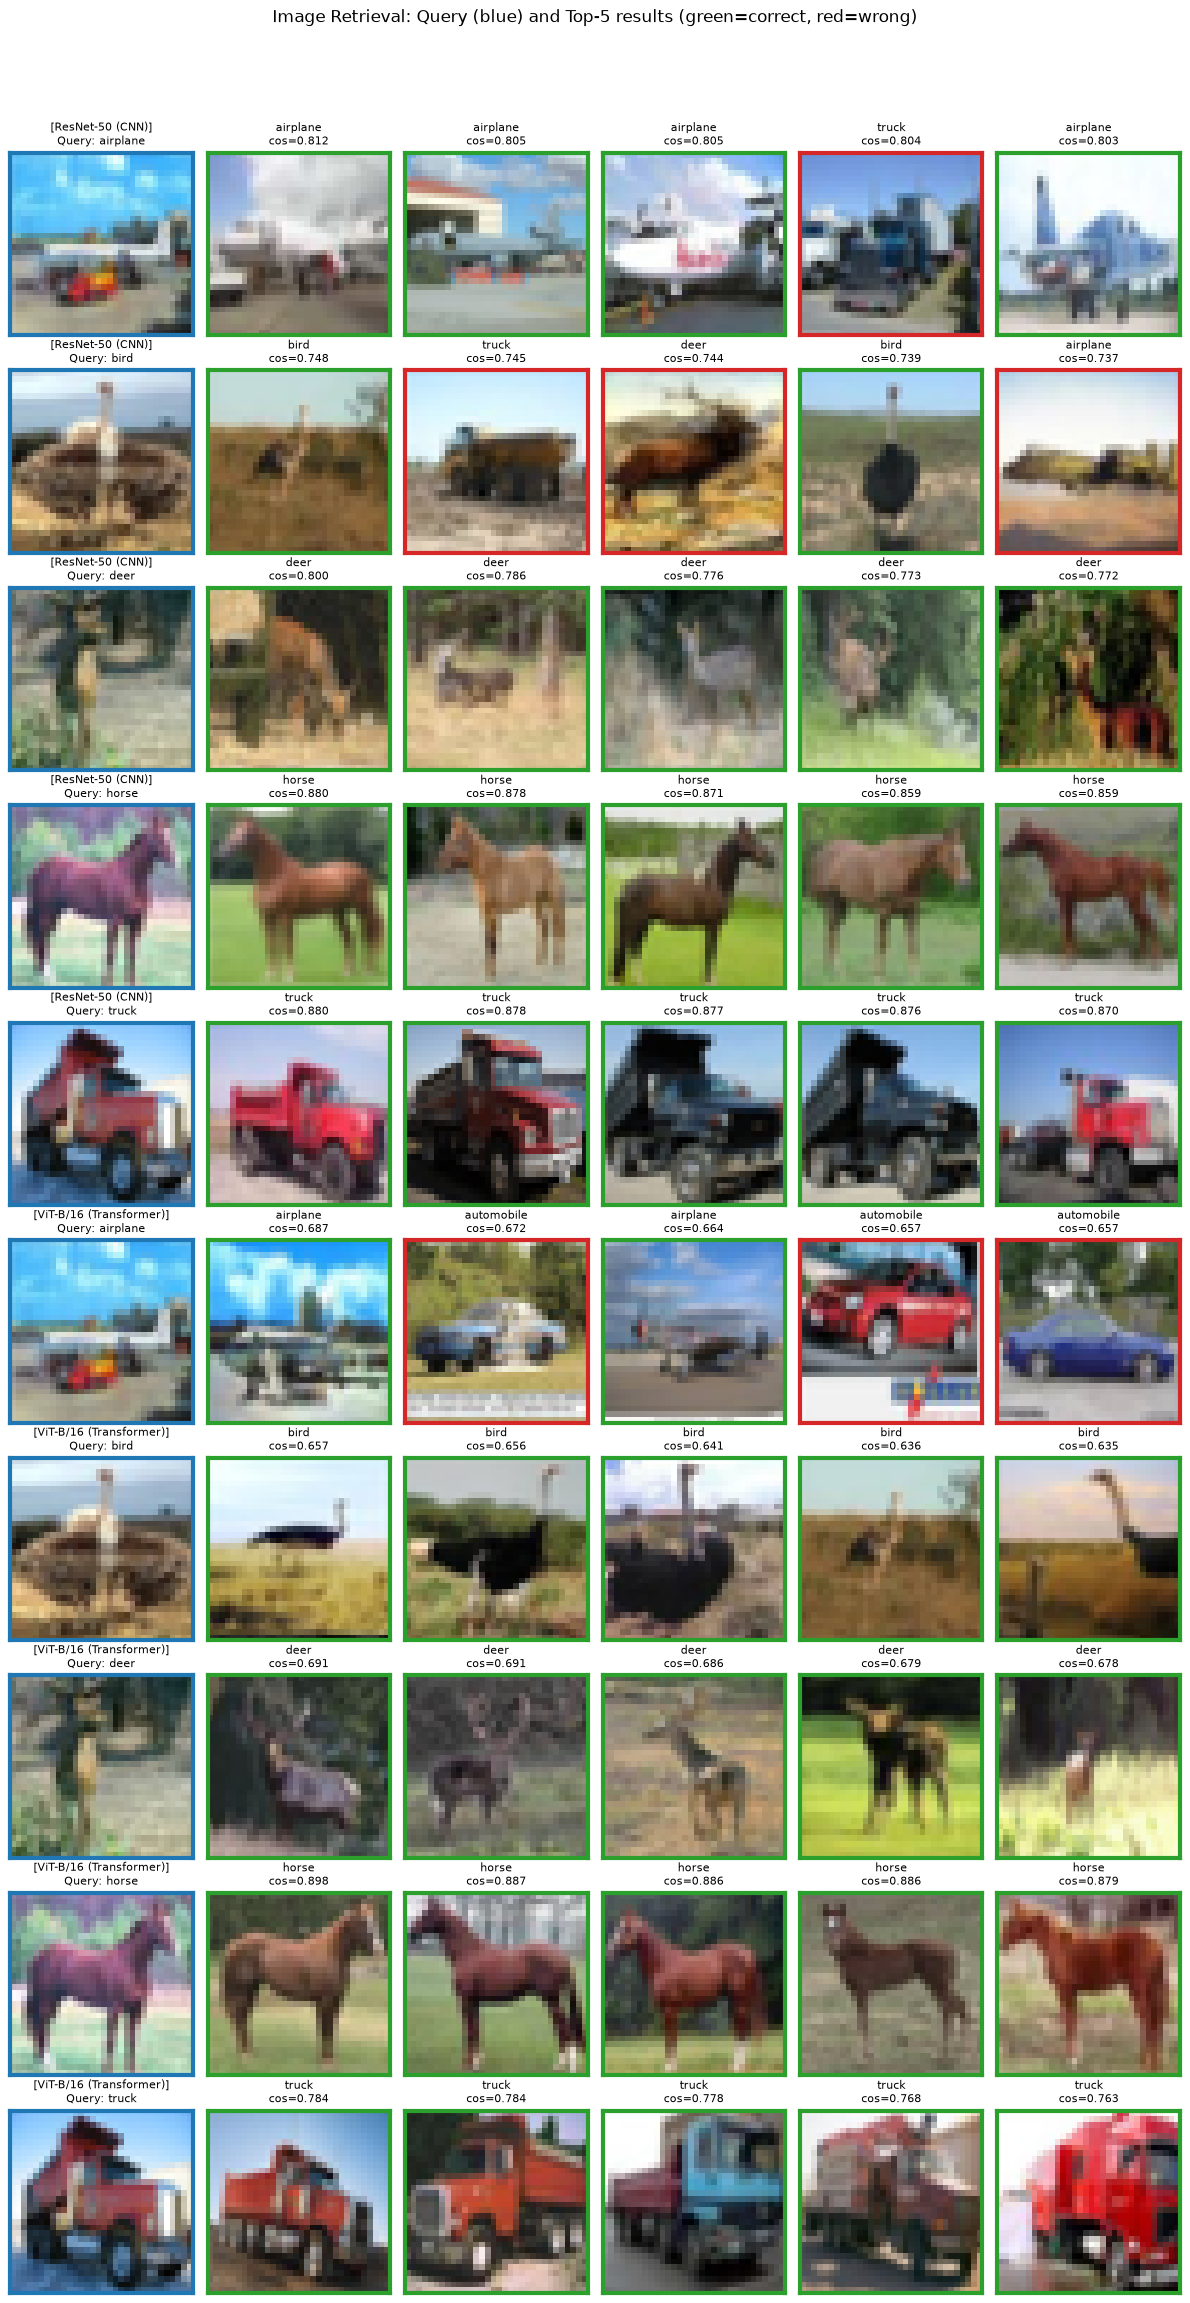

[15:41:29] INFO 檢索視覺化已儲存：/root/MMIP/MMIP/HW5/result/quiz1/retrieval_samples.png
[15:41:29] INFO 結果表格已儲存：/root/MMIP/MMIP/HW5/result/quiz1/metrics.csv


,Model,Feature Dim,Params (M),Query / Gallery,Top-1 Acc (%),Top-5 Acc (%),Precision@5 (%),Extract Time (s)
0,ResNet-50 (CNN),2048,23.51,10000 / 50000,86.01,96.27,83.05,159.0
1,ViT-B/16 (Transformer),768,85.80,10000 / 50000,93.33,98.15,91.89,179.3


In [4]:
df1 = safe_run("quiz1", run_quiz1) if "quiz1" in selected else None

## 4. Quiz 2：多模態深度學習神經網路（Hateful Memes）

#### ResNet-50 + BERT vs ViT-B/16 + BERT

[16:34:56] INFO ######## 開始 quiz2 ########


[16:34:56] INFO 資料量：train=7650, val=850, test(dev)=500
[16:34:57] INFO ===== 組合 A: ResNet-50 + BERT =====
[16:35:03] INFO 可訓練參數：1.58M / 總參數：134.57M


[16:37:25] INFO epoch 1 | train_loss 0.6567 | val_loss 0.6082 | val_acc 65.76 | val_f1 60.19


[16:39:42] INFO epoch 2 | train_loss 0.5935 | val_loss 0.5803 | val_acc 68.71 | val_f1 62.32


[16:41:57] INFO epoch 3 | train_loss 0.5482 | val_loss 0.6077 | val_acc 68.71 | val_f1 61.00


...

[16:51:14] INFO epoch 2 | train_loss 0.6031 | val_loss 0.5894 | val_acc 62.47 | val_f1 60.17


[16:53:36] INFO epoch 3 | train_loss 0.5586 | val_loss 0.5802 | val_acc 70.35 | val_f1 60.99


[16:55:57] INFO epoch 4 | train_loss 0.4972 | val_loss 0.6685 | val_acc 74.12 | val_f1 50.89


[16:58:18] INFO epoch 5 | train_loss 0.4211 | val_loss 0.6304 | val_acc 72.12 | val_f1 63.59


[16:58:27] INFO Test | acc 58.40 | f1 54.19 | macro-f1 58.04 | auroc 62.70


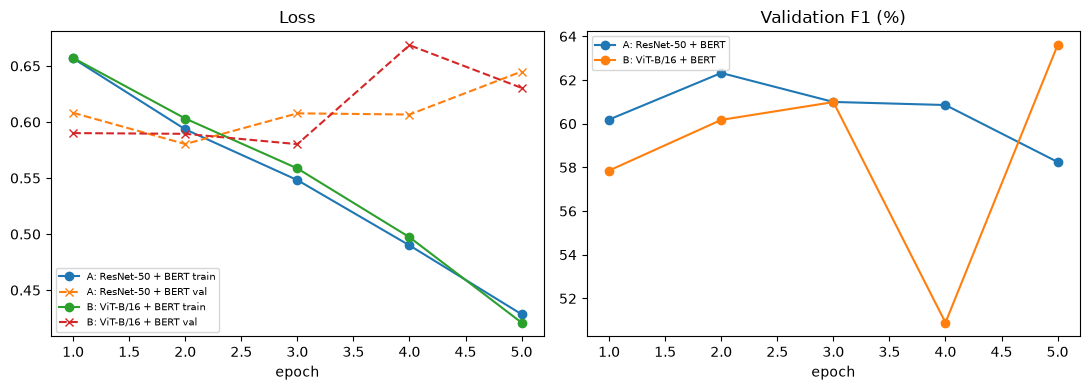

[16:58:28] INFO 訓練曲線已儲存：/root/MMIP/MMIP/HW5/result/quiz2/training_curves.png
[16:58:28] INFO 結果表格已儲存：/root/MMIP/MMIP/HW5/result/quiz2/metrics.csv


,Combination,Image Backbone,Text Backbone,Mode,Trainable Params (M),Best Epoch,Val F1 (%),Test Accuracy (%),Test F1 (%),Test Macro-F1 (%),Test AUROC (%),Train Time (s)
0,A: ResNet-50 + BERT,resnet50,bert-base-uncased,frozen backbones,1.58,2,62.32,59.8,56.77,59.60,63.3,680.2
1,B: ViT-B/16 + BERT,vit_b_16,bert-base-uncased,frozen backbones,0.92,5,63.59,58.4,54.19,58.04,62.7,704.7


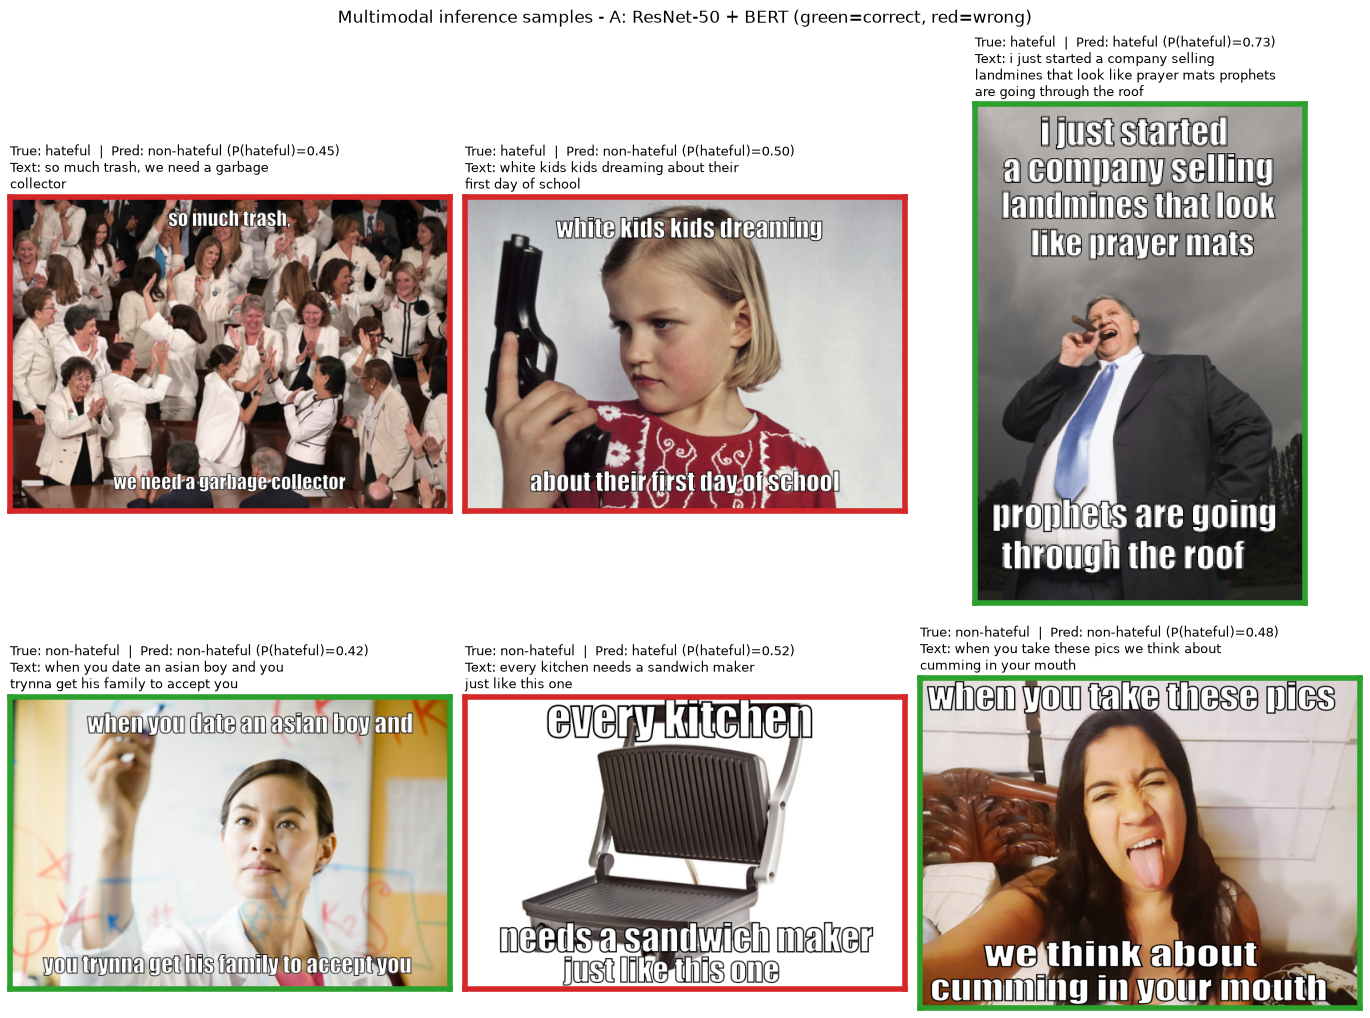

[16:58:31] INFO 結果表格已儲存：/root/MMIP/MMIP/HW5/result/quiz2/prediction_samples_A.csv


,id,text,true_label,pred_label,hateful_prob,correct
0,83045,"so much trash, we need a garbage collector",1,0,0.4497,False
1,18306,white kids kids dreaming about their first day...,1,0,0.4966,False
2,43910,i just started a company selling landmines tha...,1,1,0.7317,True
3,68401,when you date an asian boy and you trynna get ...,0,0,0.4228,True
4,16842,every kitchen needs a sandwich maker just like...,0,1,0.5211,False
5,95038,when you take these pics we think about cummin...,0,0,0.4838,True


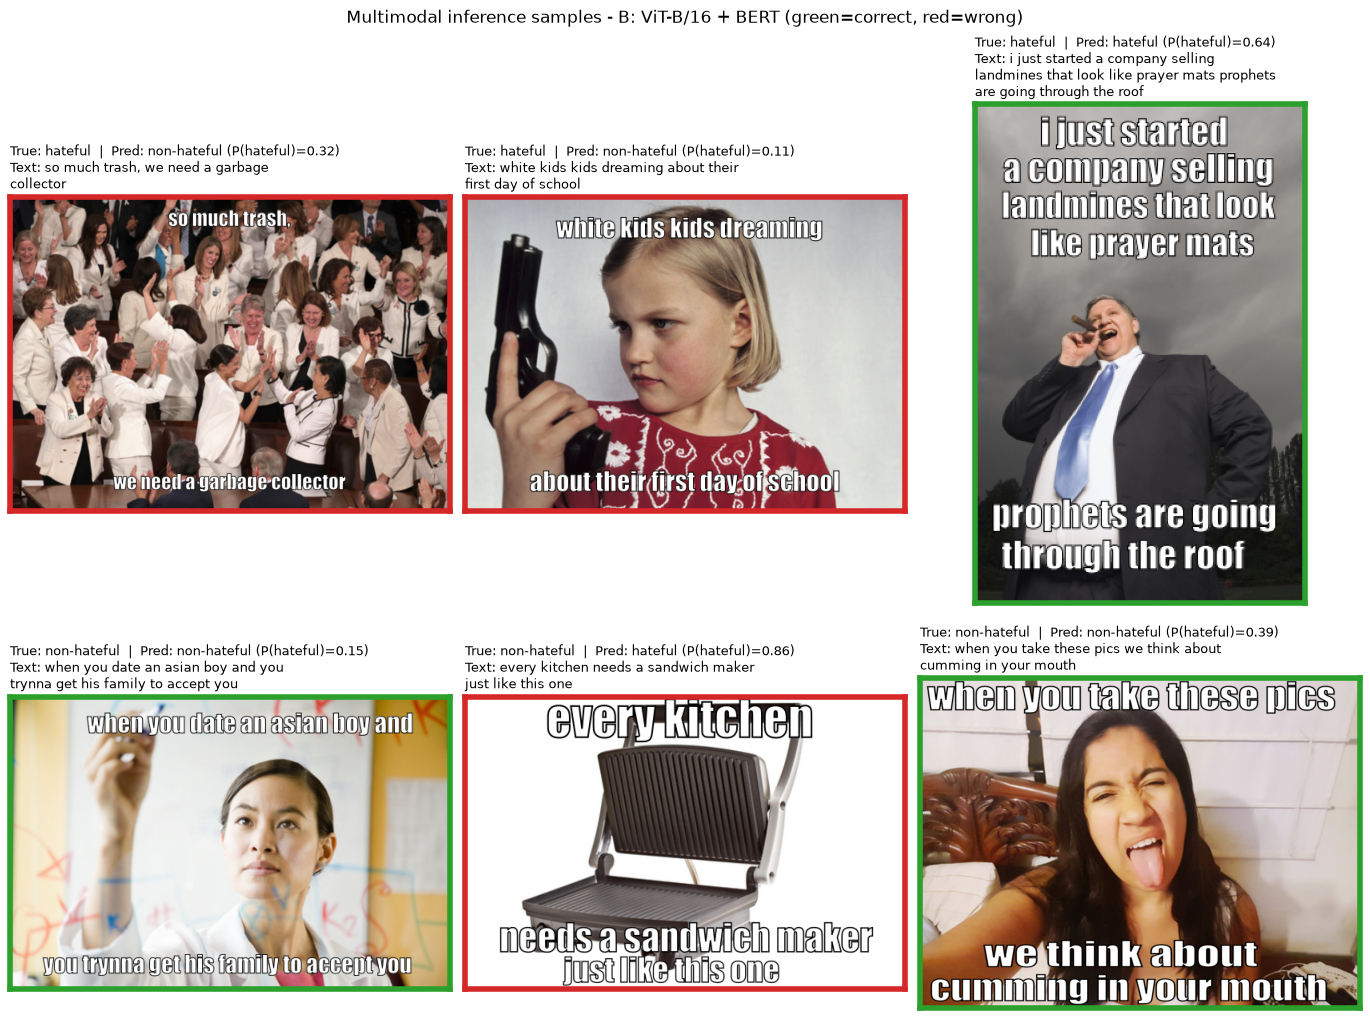

[16:58:36] INFO 結果表格已儲存：/root/MMIP/MMIP/HW5/result/quiz2/prediction_samples_B.csv


,id,text,true_label,pred_label,hateful_prob,correct
0,83045,"so much trash, we need a garbage collector",1,0,0.3189,False
1,18306,white kids kids dreaming about their first day...,1,0,0.1058,False
2,43910,i just started a company selling landmines tha...,1,1,0.6435,True
3,68401,when you date an asian boy and you trynna get ...,0,0,0.1498,True
4,16842,every kitchen needs a sandwich maker just like...,0,1,0.8628,False
5,95038,when you take these pics we think about cummin...,0,0,0.3872,True


In [4]:
df2 = safe_run("quiz2", run_quiz2) if "quiz2" in selected else None

## 5. Quiz 3：CLIP Image Captioning

Week 5 實驗：CLIP + GPT-2 影像描述  
Week 4 實驗：resnet50 + LSTM (greedy)

[16:04:56] INFO ######## 開始 quiz3 ########
[16:04:58] INFO 影像數：train=6000 val=1000 test=1000
[16:05:01] INFO 可訓練參數：155.91M（CLIP 已凍結）


[16:10:36] INFO epoch 1 | train_loss 2.6430 | val_loss 2.3050


[16:16:15] INFO epoch 2 | train_loss 2.1593 | val_loss 2.2404


[16:21:52] INFO epoch 3 | train_loss 1.9986 | val_loss 2.2329


[16:27:31] INFO epoch 4 | train_loss 1.8778 | val_loss 2.2399


[16:33:05] INFO epoch 5 | train_loss 1.7850 | val_loss 2.2647


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[16:33:43] INFO 結果表格已儲存：/root/MMIP/MMIP/HW5/result/quiz3/metrics.csv


,Metric,Week 4 Baseline,CLIP+GPT-2 (Ours),Improvement (Δ)
0,BLEU-1,0.6215,0.6733,0.0518
1,BLEU-2,0.4452,0.5009,0.0557
2,BLEU-3,0.3079,0.3608,0.0529
3,BLEU-4,0.2109,0.2518,0.0409
4,BERTScore-P,0.9271,0.9411,0.0140
5,BERTScore-R,0.9168,0.9378,0.0210
6,BERTScore-F1,0.9194,0.9367,0.0173


[16:33:43] INFO Quiz 3 訓練耗時 1684.4s，評估影像 1000 張。


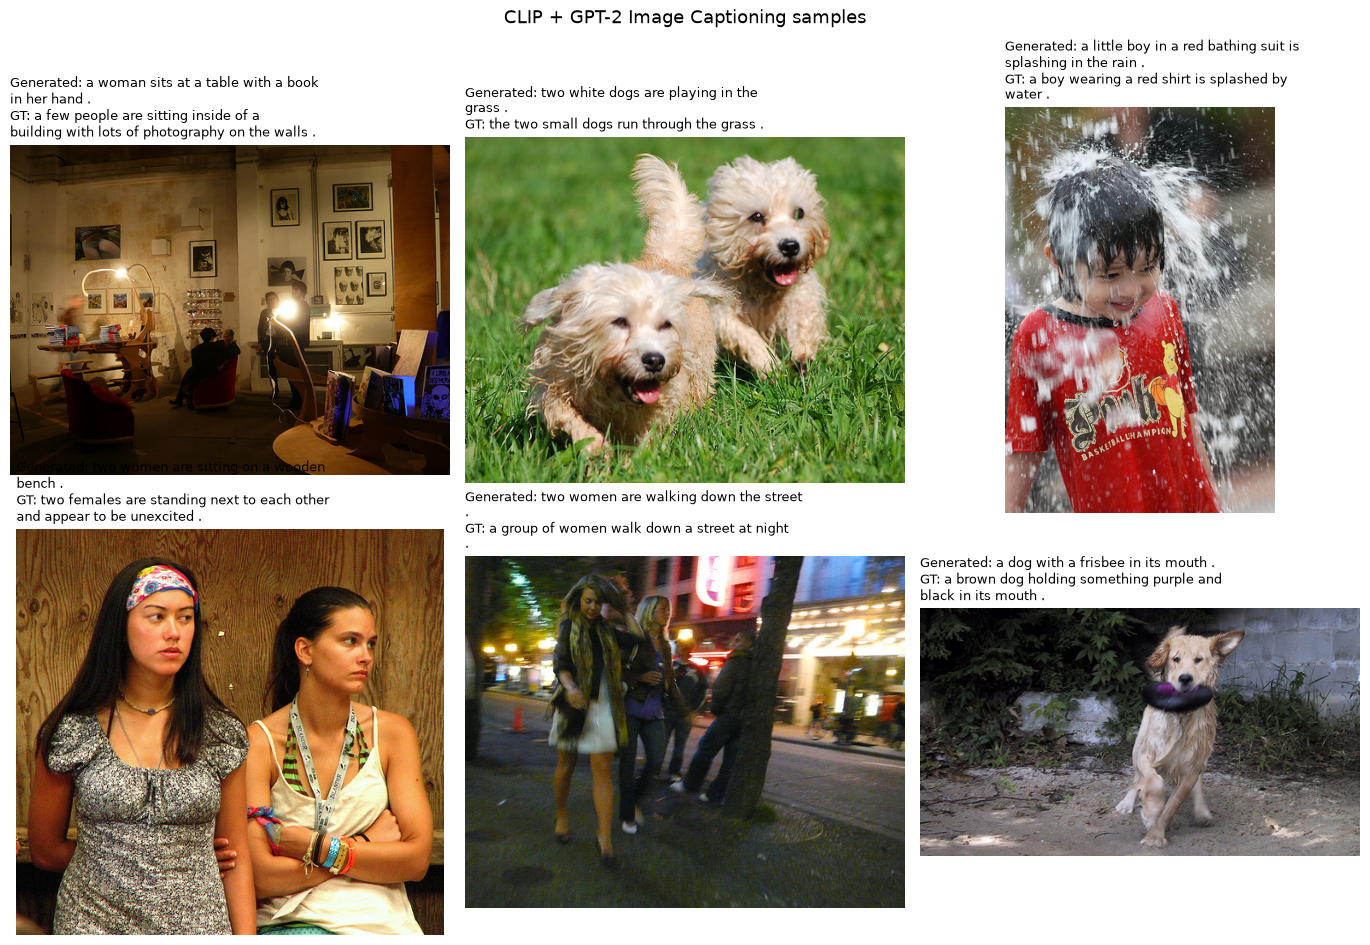

[16:33:46] INFO Caption 範例已儲存：/root/MMIP/MMIP/HW5/result/quiz3/caption_samples.png


In [6]:
df3 = safe_run("quiz3", run_quiz3) if "quiz3" in selected else None